# Pre-processing of the PLC Data (Siemens + Beckhoff)

**Goal:** Prepare the two cleaned datasets so they can be merged and used for stop detection and K-Means. Every step answers one hypothesis from `HYPOTHESES.md`.

**Input:** `siemens_cleaned.csv`, `beckhoff_cleaned.csv` (`data/processed/`)
**Output (at the end of this notebook):** `merged.csv` (`data/processed/`)

Run the cells from top to bottom (Run All).

## Load both cleaned datasets and check the time overlap (H2, part a)

### Summary

Both cleaned files are loaded. For each PLC the first time, last time, duration and median logging interval are printed. The overlap of the two recordings is calculated, because only the overlapping part can be merged. If there is no overlap, the merge is impossible.

In [2]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


======================================== SIEMENS ========================================
Shape: (6282, 143)
First time: 2019-09-26 18:21:14.515000+00:00
Last time:  2019-09-26 18:29:40.213000+00:00
Duration (s): 505.698
Median interval (ms): 76.0
======================================== BECKHOFF ========================================
Shape: (5197, 54)
First time: 2019-09-26 18:21:14.925000+00:00
Last time:  2019-09-26 18:29:40.319000+00:00
Duration (s): 505.394
Median interval (ms): 93.0

======================================== OVERLAP ========================================
Overlap start: 2019-09-26 18:21:14.925000+00:00
Overlap end:   2019-09-26 18:29:40.213000+00:00
Overlap duration (s): 505.288


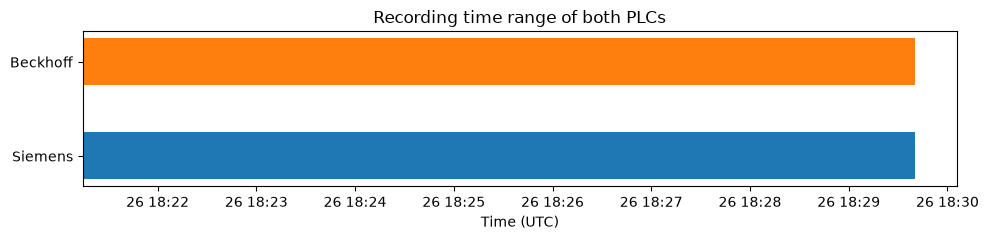

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent            # notebook lives in notebooks/
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

siemens_clean = pd.read_csv(PROCESSED_DATA_DIR / "siemens_cleaned.csv")
beckhoff_clean = pd.read_csv(PROCESSED_DATA_DIR / "beckhoff_cleaned.csv")

# Time range of each PLC
for name, df in [("SIEMENS", siemens_clean), ("BECKHOFF", beckhoff_clean)]:
    ts = df["timestamp"]
    print("=" * 40, name, "=" * 40)
    print("Shape:", df.shape)
    print("First time:", pd.to_datetime(ts.iloc[0], unit="ms", utc=True))
    print("Last time: ", pd.to_datetime(ts.iloc[-1], unit="ms", utc=True))
    print("Duration (s):", (ts.iloc[-1] - ts.iloc[0]) / 1000)
    print("Median interval (ms):", ts.diff().median())

# Overlap of the two recordings
overlap_start = max(siemens_clean["timestamp"].iloc[0], beckhoff_clean["timestamp"].iloc[0])
overlap_end = min(siemens_clean["timestamp"].iloc[-1], beckhoff_clean["timestamp"].iloc[-1])
overlap_seconds = (overlap_end - overlap_start) / 1000

print("\n" + "=" * 40, "OVERLAP", "=" * 40)
print("Overlap start:", pd.to_datetime(overlap_start, unit="ms", utc=True))
print("Overlap end:  ", pd.to_datetime(overlap_end, unit="ms", utc=True))
print("Overlap duration (s):", overlap_seconds)

# Plot: both recordings on one time axis
fig, ax = plt.subplots(figsize=(10, 2.5))
for row, (name, df) in enumerate([("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]):
    start = pd.to_datetime(df["timestamp"].iloc[0], unit="ms", utc=True)
    end = pd.to_datetime(df["timestamp"].iloc[-1], unit="ms", utc=True)
    ax.barh(row, end - start, left=start, height=0.5, label=name)
ax.set_yticks([0, 1])
ax.set_yticklabels(["Siemens", "Beckhoff"])
ax.set_xlabel("Time (UTC)")
ax.set_title("Recording time range of both PLCs")
plt.tight_layout()
plt.show()

## Choose the common time grid (H1)

### Summary

The two PLCs log at different, irregular intervals, so both must be put on one regular time grid before merging. If the grid is too coarse, a short ON pulse that starts and ends between two grid points disappears. For each PLC and for grid sizes of 20, 50, 100 and 200 ms, the boolean signals are resampled (each grid point takes the last known value, no interpolation), and the ON/OFF changes before and after are counted. The loss in percent shows how much information each grid destroys.


Siemens: 125 boolean signals, 2023.0 changes in the raw data
Beckhoff: 50 boolean signals, 4438.0 changes in the raw data

Lost signal changes (%):
         Siemens  Beckhoff
grid_ms                   
20          0.00      0.00
50          0.00      0.00
100         7.02      4.01
200        18.49     33.66


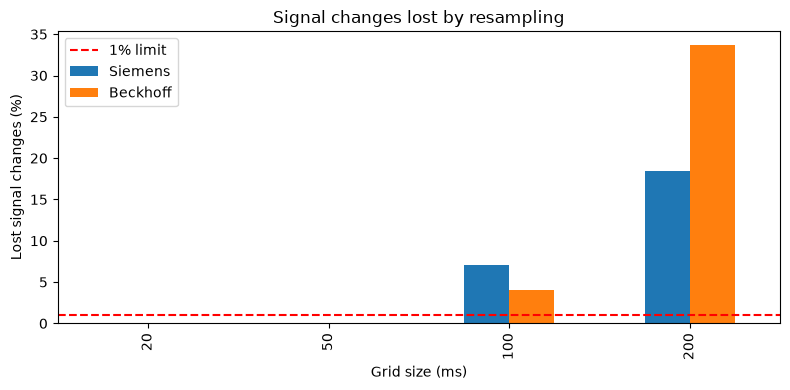

Coarsest grid with loss < 1% in both PLCs: 50


In [4]:
import numpy as np

grid_sizes = [20, 50, 100, 200]          # candidate grid sizes in ms
loss_table = pd.DataFrame(index=grid_sizes, columns=["Siemens", "Beckhoff"], dtype=float)
loss_table.index.name = "grid_ms"

for name, df in [("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]:
    # only boolean signals: count their ON/OFF changes
    signals = df.drop(columns="timestamp").select_dtypes(include="bool")
    edges_raw = signals.astype(int).diff().abs().sum().sum()
    ts = df["timestamp"].values

    for step in grid_sizes:
        grid = np.arange(ts[0], ts[-1], step)
        # last known value at each grid point (forward fill, no interpolation)
        position = np.searchsorted(ts, grid, side="right") - 1
        edges_grid = signals.iloc[position].astype(int).diff().abs().sum().sum()
        loss_table.loc[step, name] = (edges_raw - edges_grid) / edges_raw * 100

    print(f"{name}: {signals.shape[1]} boolean signals, {edges_raw} changes in the raw data")

print("\nLost signal changes (%):")
print(loss_table.round(2).to_string())

# Plot
ax = loss_table.plot(kind="bar", figsize=(8, 4))
ax.axhline(1, color="red", linestyle="--", label="1% limit")
ax.set_xlabel("Grid size (ms)")
ax.set_ylabel("Lost signal changes (%)")
ax.set_title("Signal changes lost by resampling")
ax.legend()
plt.tight_layout()
plt.show()

# Decision rule: coarsest grid with loss < 1% in both PLCs
accepted = loss_table[(loss_table < 1).all(axis=1)]
print("Coarsest grid with loss < 1% in both PLCs:",
      accepted.index.max() if not accepted.empty else "none")

## Step 3 – Check the clock offset between the PLCs

### Summary

Each PLC records timestamps using its own clock. If the clocks are not synchronized, the same physical event can have different timestamps in the two datasets.

Both PLCs are aligned to the common 50 ms time grid selected in Step 2. For each PLC, the number of signal changes per grid step (activity) is calculated.

The Siemens activity curve is shifted against the Beckhoff activity curve from -2 seconds to +2 seconds. The correlation is calculated for each shift. The shift with the highest correlation is taken as the estimated clock offset.


Best shift (steps): 40
Estimated offset (ms): 2000
Correlation at best shift: 0.024
Correlation at shift 0: 0.003
Typical (median) correlation: -0.001
Within one grid step (no correction needed): False


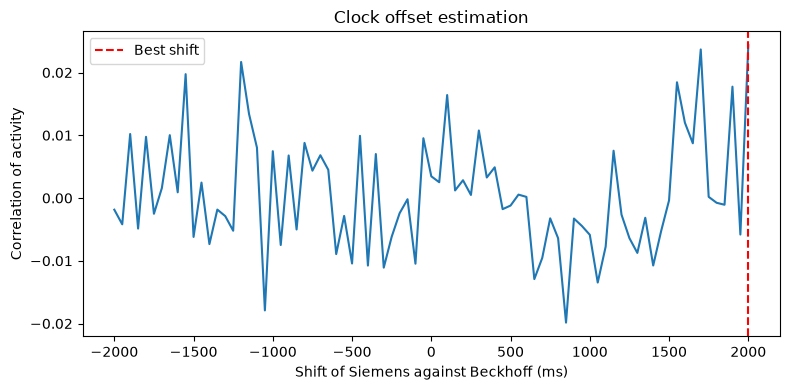

In [5]:

# Step 3: Estimate clock offset between Siemens and Beckhoff

grid_ms = 50  # Selected common grid from Step 2
grid = np.arange(overlap_start, overlap_end, grid_ms)

# Check that timestamps are sorted
siemens_clean = siemens_clean.sort_values("timestamp").reset_index(drop=True)
beckhoff_clean = beckhoff_clean.sort_values("timestamp").reset_index(drop=True)

# Calculate activity (number of signal changes per grid step)
activity = {}

for name, df in [("Siemens", siemens_clean), ("Beckhoff", beckhoff_clean)]:

    signals = df.drop(columns="timestamp").select_dtypes(include="bool")

    ts = df["timestamp"].values

    position = np.searchsorted(ts, grid, side="right") - 1

    # Last known signal value at each grid point
    sampled = signals.iloc[position].astype(int)

    # Count signal changes per grid step
    changes = sampled.diff().abs().sum(axis=1).fillna(0)

    activity[name] = changes.values

# Correlation for shifts from -2 seconds to +2 seconds
max_lag = 40  # 40 x 50 ms = 2 seconds

lags = list(range(-max_lag, max_lag + 1))
corr = []

for lag in lags:

    if lag >= 0:
        a = activity["Siemens"][lag:]
        b = activity["Beckhoff"][:len(activity["Beckhoff"]) - lag]
    else:
        a = activity["Siemens"][:lag]
        b = activity["Beckhoff"][-lag:]

    # Avoid correlation when there is no variation
    if len(a) < 2 or np.std(a) == 0 or np.std(b) == 0:
        corr.append(np.nan)
    else:
        corr.append(np.corrcoef(a, b)[0, 1])

# Find shift with highest valid correlation
corr = np.array(corr)

if not np.isfinite(corr).any():
    raise ValueError("Could not calculate valid correlations.")

best_index = np.nanargmax(corr)
best_lag = lags[best_index]

print("Best shift (steps):", best_lag)
print("Estimated offset (ms):", best_lag * grid_ms)
print("Correlation at best shift:", round(corr[best_index], 3))
print("Correlation at shift 0:", round(corr[max_lag], 3))
print("Typical (median) correlation:", round(float(np.nanmedian(corr)), 3))
print("Within one grid step (no correction needed):", abs(best_lag) <= 1)

# Plot correlation against time shift
plt.figure(figsize=(8, 4))

plt.plot([lag * grid_ms for lag in lags], corr)
plt.axvline(best_lag * grid_ms, color="red",
            linestyle="--", label="Best shift")

plt.xlabel("Shift of Siemens against Beckhoff (ms)")
plt.ylabel("Correlation of activity")
plt.title("Clock offset estimation")

plt.legend()
plt.tight_layout()
plt.show()


In [6]:
# Inspect activity patterns

for name in ["Siemens", "Beckhoff"]:

    values = activity[name]

    print(f"\n===== {name} =====")

    print("Total grid points:", len(values))
    print("Total signal changes:", np.sum(values))
    print("Mean activity:", np.mean(values))
    print("Standard deviation:", np.std(values))
    print("Maximum activity:", np.max(values))
    print("Percentage of zero activity:",
          np.mean(values == 0) * 100)


===== Siemens =====
Total grid points: 10106
Total signal changes: 2023.0
Mean activity: 0.20017811201266575
Standard deviation: 0.8500264649026334
Maximum activity: 14.0
Percentage of zero activity: 90.8074411240847

===== Beckhoff =====
Total grid points: 10106
Total signal changes: 4438.0
Mean activity: 0.4391450623392044
Standard deviation: 0.9961867833872668
Maximum activity: 8.0
Percentage of zero activity: 76.14288541460519


### Conclusion – Clock Offset Estimation

The activity-based correlation analysis did not reveal a meaningful relationship between Siemens and Beckhoff activity patterns. The maximum correlation was only 0.024, indicating that a reliable clock offset could not be estimated using this method.

Therefore, no timestamp correction is applied. We proceed with merging both datasets using the common 50 ms time grid, while noting that clock synchronization could not be independently verified.

## Step 4 – Merge Siemens and Beckhoff datasets


Both PLC datasets are aligned to the common 50 ms time grid. The last available observation is carried forward to each grid point without interpolation.

The two datasets are then merged using their common timestamps. Siemens and Beckhoff signal columns are given separate prefixes to identify their source and avoid duplicate column names.

No clock correction is applied because the activity-based correlation analysis could not reliably estimate the relative clock offset. Therefore, temporal synchronization remains unverified.

In [7]:

# Step 4: Merge Siemens and Beckhoff datasets

grid_ms = 50
grid = np.arange(overlap_start, overlap_end, grid_ms)


# Function to align each PLC dataset to the common grid
def align_to_grid(df, name):

    df = df.sort_values("timestamp").reset_index(drop=True)

    ts = df["timestamp"].values

    # Find the last available observation at each grid point
    position = np.searchsorted(ts, grid, side="right") - 1

    if np.any(position < 0):
        raise ValueError(f"{name}: Grid contains timestamps before available data.")

    # Sample all signal columns at the grid positions
    aligned = df.drop(columns="timestamp").iloc[position].reset_index(drop=True)

    # Add PLC prefix to signal names
    aligned.columns = [f"{name}_{col}" for col in aligned.columns]

    # Add common timestamp
    aligned.insert(0, "timestamp", grid)

    return aligned


# Align both PLC datasets
siemens_aligned = align_to_grid(siemens_clean, "Siemens")
beckhoff_aligned = align_to_grid(beckhoff_clean, "Beckhoff")


# Merge using the common timestamp
merged = pd.merge(
    siemens_aligned,
    beckhoff_aligned,
    on="timestamp",
    how="inner"
)


# Sort by timestamp
merged = merged.sort_values("timestamp").reset_index(drop=True)


# Display results
print("Merged dataset shape:", merged.shape)
print("\nFirst 5 rows:")
display(merged.head())

print("\nMissing values:")
print(merged.isna().sum().sum())

# Save merged dataset
OUTPUT_PATH = PROCESSED_DATA_DIR / "merged.csv"

merged.to_csv(OUTPUT_PATH, index=False)

print("\nMerged dataset saved to:", OUTPUT_PATH)


Merged dataset shape: (10106, 196)

First 5 rows:


C:\Users\srbar\AppData\Local\Temp\ipykernel_16064\1572771212.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  aligned.insert(0, "timestamp", grid)


,timestamp,Siemens_M34.4,Siemens_M24.7,Siemens_M25.3,Siemens_M25.4,Siemens_I200.7,Siemens_M38.0,Siemens_M38.1,Siemens_A0.1,Siemens_A0.0,...,Beckhoff_VG.Q5_rotClockwise,Beckhoff_VG.Q6_rotCounterClockwise,Beckhoff_VG.Q7_compressorON,Beckhoff_VG.Q8_valve,Beckhoff_Pallets.Conveyor_belt_lift,Beckhoff_VG.atHome,Beckhoff_VG.error_robot,Beckhoff_WH.isEmpty,Beckhoff_WH.desiredPalletX,Beckhoff_WH.desiredPalletY
0,1569522074925,False,False,True,False,False,False,False,False,False,...,False,False,False,False,800,False,False,False,1620,110
1,1569522074975,False,False,True,False,False,False,False,False,False,...,False,False,False,False,800,False,False,False,1620,110
2,1569522075025,False,False,True,False,False,False,False,False,False,...,False,False,False,False,800,False,False,False,1620,110
3,1569522075075,False,False,True,False,False,False,False,False,False,...,False,False,False,False,800,False,False,False,1620,110
4,1569522075125,False,False,True,False,False,False,False,False,False,...,False,False,False,False,800,False,False,False,1620,110



Missing values:
0

Merged dataset saved to: s:\albstadt sigmaringen university\winter sem 26 27\Project B4\Performance_loss_mini_project-1\applied-industrial-ai-manufacturing\data\processed\merged.csv
